# Week 14 — What to Remember

Build an LSTM from the NumPy autograd engine and train it to predict the next character. Run from `week14` with `data/qa_oldtongue.txt` installed as described in the README. The source cells copy the existing Python files verbatim; NumPy is the only external library they import.

## Part 1 — Extend the Engine

`index_select` looks up rows and adds their gradients back. Cross-entropy measures the mean prediction loss, while the engine carries gradients through the shared graph.

In [1]:
import numpy as np

class Tensor:
    def __init__(self, data, autograd=False, creators=None, creation_op=None, id=None):
        self.data = np.array(data)
        self.creators = creators
        self.creation_op = creation_op
        self.grad = None
        self.autograd = autograd

        if id:
            self.id = id
        else:
            self.id = np.random.randint(0,100000)

        self.children = {}
        if creators is not None:
            for c in creators:
                if self.id not in c.children:
                    c.children[self.id] = 1
                else:
                    c.children[self.id] += 1

    def __repr__(self):
        return str(self.data)

    def __str__(self):
        return str(self.data)

    def all_children_accounted_for(self):
        for id in self.children:
            if self.children[id] != 0:
                return False
        return True

    def backward(self, grad = None, grad_origin = None):
        # If self.autograd is false, return a plain tensor takes no part in the walk
        if not self.autograd:
            return

        # If grad is None, start from ones
        if grad is None:
            grad = Tensor(np.ones_like(self.data))

        # If grad_origin is given, a child is reporting. 
        # If that child’s counter is already zero, raise Exception("cannot backprop more than once"); 
        # otherwise decrement it
        if grad_origin:
            if self.children[grad_origin.id] == 0:
                raise Exception("cannot backprop more than once")
            else:
                self.children[grad_origin.id] -= 1

        # Accumulate into self.grad with += rather than overwriting.
        if self.grad is None:
            self.grad = grad
        elif self.grad:
            self.grad += grad

        # Only recurse into creators once all_children_accounted_for() is true, or grad_origin is None
        if self.all_children_accounted_for() or grad_origin is None:
            if self.creation_op is None:
                return
            elif self.creation_op == "add":
                self.creators[0].backward(grad = self.grad, grad_origin = self)
                self.creators[1].backward(grad = self.grad, grad_origin = self)
            elif self.creation_op == "neg":
                self.creators[0].backward(-self.grad, self)
            elif self.creation_op == "sub":
                self.creators[0].backward(self.grad, self)
                self.creators[1].backward(self.grad, self)
            elif self.creation_op == "mul":
                self.creators[0].backward(self.grad * self.creators[1], self)
                self.creators[1].backward(self.grad * self.creators[0], self)
            elif self.creation_op == "mm":
                c0, c1 = self.creators
                c0.backward(Tensor(self.grad.data.dot(c1.data.T)), self)
                c1.backward(Tensor(c0.data.T.dot(self.grad.data)), self)
            elif self.creation_op == "transpose":
                self.creators[0].backward(self.grad.T, self)
            elif "sum" in self.creation_op:
                dim = int(self.creation_op.split("_")[1])
                ds = self.creators[0].data.shape[dim]
                self.creators[0].backward(self.grad.expand(dim, ds), self)
            elif "expand" in self.creation_op:
                dim = int(self.creation_op.split("_")[1])
                self.creators[0].backward(self.grad.sum(dim), self)
            elif self.creation_op == "tanh":
                ones = Tensor(np.ones_like(self.grad.data))
                self.creators[0].backward(grad = self.grad * (ones - self*self), grad_origin = self)
            elif self.creation_op == "sigmoid":
                ones = Tensor(np.ones_like(self.grad.data))
                self.creators[0].backward(grad = self.grad * self * (ones - self), grad_origin = self)
            elif self.creation_op == "index_select":
                inds = self.index_select_indices.data
                with_zeroed = np.zeros_like(self.creators[0].data)
                np.add.at(with_zeroed, inds, self.grad.data)
                self.creators[0].backward(grad=Tensor(with_zeroed), grad_origin = self)
            elif self.creation_op == "cross_entropy":
                gradient = (self.softmax_output - self.target_dist) / len(self.target_dist)
                self.creators[0].backward(grad=Tensor(gradient * self.grad.data), grad_origin=self)


    def __add__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data + other.data, autograd = True, creators = [self, other], creation_op = "add")
        else:
            return Tensor(self.data + other.data)

    def __sub__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data - other.data, autograd = True, creators = [self, other], creation_op = "sub")
        else:
            return Tensor(self.data - other.data)

    def __mul__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data * other.data, autograd = True, creators = [self, other], creation_op = "mul")
        else:
            return Tensor(self.data * other.data)

    def __neg__(self):
        if self.autograd:
            return Tensor(self.data * -1, autograd = True, creators = [self], creation_op = "neg")
        else:
            return Tensor(self.data * -1)

    def __matmul__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data.dot(other.data), autograd = True, creators = [self, other], creation_op = "mm")
        else:
            return Tensor(self.data.dot(other.data))

    @property
    def T(self):
        return self.transpose()

    def mm(self, other):
        return self @ other
    
    def transpose(self):
        if self.autograd:
            return Tensor(self.data.T, autograd = True, creators = [self], creation_op = "transpose")
        else:
            return Tensor(self.data.T)

    def sum(self, dim):
        if self.autograd:
            return Tensor(np.sum(self.data, dim), autograd = True, creators = [self], creation_op = f"sum_{dim}")
        else:
            return Tensor(np.sum(self.data, dim))

    def expand(self, dim, n):
        trans_cmd = list(range(0, len(self.data.shape)))
        trans_cmd.insert(dim, len(self.data.shape))
        new_data = self.data.repeat(n).reshape(list(self.data.shape) + [n]).transpose(trans_cmd)
        
        if not self.autograd:
            return Tensor(new_data)
        
        return Tensor(new_data, autograd = True, creators = [self], creation_op = f"expand_{dim}")


    def tanh(self):
        if self.autograd:
            return Tensor(np.tanh(self.data), autograd = True, creators = [self], creation_op = "tanh")
        else:
            return Tensor(np.tanh(self.data))

    def sigmoid(self):
        if self.autograd:
            return Tensor(1 / (1 + np.exp(-self.data)), autograd = True, creators = [self], creation_op = "sigmoid")
        else:
            return Tensor(1 / (1 + np.exp(-self.data)))

    def index_select(self, indices):
        if self.autograd:
            indices_tensor = Tensor(self.data[indices.data], autograd = True, creators = [self], creation_op = "index_select")
            indices_tensor.index_select_indices = indices
            return indices_tensor
        else:
            return Tensor(self.data[indices.data])

    def softmax(self):
        expd = np.exp(self.data - np.max(self.data))
        soft = expd / np.sum(expd)
        return Tensor(soft)

    def cross_entropy(self, target_indices):
        temp = np.exp(self.data)
        softmax_output = temp / np.sum(temp, axis=len(self.data.shape) - 1,
keepdims=True)
        t = target_indices.data.flatten()
        p = softmax_output.reshape(len(t), -1)
        target_dist = np.eye(p.shape[1])[t]
        loss = -(np.log(p) * target_dist).sum(1).mean()
        if self.autograd:
            out = Tensor(loss, autograd=True, creators=[self],
creation_op="cross_entropy")
            out.softmax_output = softmax_output
            out.target_dist = target_dist
            return out
        return Tensor(loss)

### Explain it — Repeated indices

With assignment instead of addition, the selection counts would be `[0, 1, 1, 1, 1]` rather than `[0, 1, 2, 2, 1]`. Each selected row contains five ones in the backward gradient, so the actual row sums would be `[0, 5, 5, 5, 5]` instead of `[0, 5, 10, 10, 5]`. Assignment overwrites the earlier contribution when rows 2 and 3 appear again.

### Explain it — Mean loss

The forward loss averages over the rows, so its gradient must also divide by that number. Leaving the division out makes the update 16 times larger for a batch of 16, which can make training unstable at the same learning rate.

## Part 2 — The Lookup and the Loss

The embedding is a trainable row lookup, and the loss wrapper calls the tensor operation. The layer file also contains Part 4's LSTM. SGD is carried forward unchanged.

In [2]:
class SGD:
    def __init__(self, parameters, alpha):
        self.parameters = parameters
        self.alpha = alpha

    def step(self, zero=True):
        for p in self.parameters:
            p.data -= p.grad.data * self.alpha
            if zero:
                p.grad.data *= 0


In [3]:
import numpy as np
from tensor import Tensor


class Layer:
    def __init__(self):
        self.parameters = []

    def get_parameters(self):
        return self.parameters


class Linear(Layer):
    def __init__(self, n_in, n_out, bias = True):
        super().__init__()
        W = np.random.randn(n_in, n_out) * np.sqrt(2.0 / n_in)
        self.weight = Tensor(W, autograd=True)
        if bias:
            self.bias = Tensor(np.zeros(n_out), autograd=True)
        else:
            self.bias = None
        self.parameters.append(self.weight)
        if bias:
            self.parameters.append(self.bias)

    def forward(self, input):
        if self.bias:
            return input.mm(self.weight) + self.bias.expand(0, len(input.data))
        else:
            return input.mm(self.weight)

class Embedding(Layer):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.vocab_size = vocab_size
        self.dim = dim
        
        self.weight = Tensor((np.random.rand(vocab_size, dim) - 0.5) / dim, autograd=True)
        self.parameters.append(self.weight)

    def forward(self, input):
        return self.weight.index_select(input)

class CrossEntropyLoss:
    def __init__(self):
        super().__init__()
        
    def forward(self, input, target):
        return input.cross_entropy(target)

class Sequential(Layer):
    def __init__(self, layers):
        super().__init__()
        self.layers = layers

    def forward(self, input):
        for layer in self.layers:
            input = layer.forward(input)
        return input

    def get_parameters(self):
        parameters = []
        for layer in self.layers:
            parameters.extend(layer.get_parameters())
        return parameters

class LSTMCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output):
        super().__init__()
        self.n_inputs, self.n_hidden, self.n_output = n_inputs, n_hidden, n_output
        # input -> gate (with bias)
        self.xf = Linear(n_inputs, n_hidden)
        self.xi = Linear(n_inputs, n_hidden)
        self.xo = Linear(n_inputs, n_hidden)
        self.xc = Linear(n_inputs, n_hidden)
        # hidden -> gate (no bias)
        self.hf = Linear(n_hidden, n_hidden, bias=False)
        self.hi = Linear(n_hidden, n_hidden, bias=False)
        self.ho = Linear(n_hidden, n_hidden, bias=False)
        self.hc = Linear(n_hidden, n_hidden, bias=False)
        # cell view -> logits (bias-free)
        self.w_ho = Linear(n_hidden, n_output, bias=False)
        for layer in (self.xf, self.xi, self.xo, self.xc,
                      self.hf, self.hi, self.ho, self.hc, self.w_ho):
            self.parameters += layer.get_parameters() # in this order

    def forward(self, input, hidden: tuple[Tensor, Tensor]):
        prev_hidden, prev_cell = hidden[0], hidden[1]
        f = (self.xf.forward(input) + self.hf.forward(prev_hidden)).sigmoid()
        i = (self.xi.forward(input) + self.hi.forward(prev_hidden)).sigmoid()
        o = (self.xo.forward(input) + self.ho.forward(prev_hidden)).sigmoid()
        g = (self.xc.forward(input) + self.hc.forward(prev_hidden)).tanh()
        c = (f * prev_cell) + (i * g)
        h = o * c.tanh()
        return self.w_ho.forward(h), (h, c)

    def init_hidden(self, batch_size=1):
        h = Tensor(np.zeros((batch_size, self.n_hidden)), autograd=True)
        c = Tensor(np.zeros((batch_size, self.n_hidden)), autograd=True)
        h.data[:, 0] += 1; c.data[:, 0] += 1
        return (h, c)
    

class Tanh(Layer):
    def __init__(self):
        super().__init__()
    
    def forward(self, input):
        return input.tanh()

class Sigmoid(Layer):
    def __init__(self):
        super().__init__()

    def forward(self, input):
        return input.sigmoid()

class MSELoss(Layer):
    def __init__(self):
        super().__init__()

    def forward(self, pred, target):
        return ((pred-target)*(pred-target)).sum(0)



### Explain it — One bias per gate

Each input-to-gate projection already supplies a bias before the gate activation. A second bias on the hidden projection would only add another constant to the same sum, so it gives a redundant parameterization and changes the training updates.

## Part 3 — Vanishing, Exploding, and the Gate

Repeated sigmoid derivatives shrink the backward signal, while the ReLU example multiplies it by five per step. The cell-state comparison uses identical random writes with the forget gate on and with it forced to one.

In [4]:
import numpy as np

sigmoid = lambda x: 1 / (1 + np.exp(-x))
relu = lambda x: (x > 0).astype(float) * x
W = np.array([[1, 4], [4, 1]]) 

def vanishing(steps = 10):
    activation = sigmoid(np.array([1, 0.01]))
    acts = []

    for _ in range(steps):
        activation = sigmoid(activation.dot(W)); acts.append(activation)
    grads, gradient = [], np.ones(2)

    for act in reversed(acts): # sigmoid derivative a*(1-a)
        gradient = (act * (1 - act) * gradient).dot(W.T)
        grads.append(gradient.copy())

    return grads

def exploding(steps=10):
    activation = sigmoid(np.array([1, 0.01]))
    acts = []

    for _ in range(steps):
        activation = relu(activation.dot(W)); acts.append(activation)
    grads, gradient = [], np.ones(2)
    
    for act in reversed(acts): # relu mask: nothing clamps
        gradient = ((act > 0) * gradient).dot(W.T)
        grads.append(gradient.copy())

    return grads

def lstm_cell_state_horizon(steps=50, forget_gate=True, seed=0):
    rng = np.random.RandomState(seed)
    c, norms = np.zeros(16), []

    for _ in range(steps):
        x = rng.randn(16)
        f_pre = rng.randn(16) # always drawn: same writes either way
        f = sigmoid(f_pre) if forget_gate else np.ones(16)
        i = sigmoid(rng.randn(16))
        c = f * c + i * np.tanh(x) # keep f of the old, write i of the new
        norms.append(float(np.max(np.abs(c))))

    return norms

if __name__ == "__main__":
    gv = vanishing(10)
    print("VANISHING (sigmoid):")
    print(" |grad| step 1 = {:.4f}".format(np.max(np.abs(gv[0]))))
    print(" |grad| step 10 = {:.3e}".format(np.max(np.abs(gv[-1]))))
    
    ge = exploding(10)
    mags = [int(round(np.max(np.abs(g)))) for g in ge]
    print("EXPLODING (relu):")
    print(" |grad|:", mags)
    print(" 5**10 =", 5 ** 10, " -> match:", mags[-1] == 5 ** 10)



VANISHING (sigmoid):
 |grad| step 1 = 0.0344
 |grad| step 10 = 2.169e-14
EXPLODING (relu):
 |grad|: [5, 25, 125, 625, 3125, 15625, 78125, 390625, 1953125, 9765625]
 5**10 = 9765625  -> match: True


In [5]:
gated = lstm_cell_state_horizon(50, True)
ungated = lstm_cell_state_horizon(50, False)
print("Step 1: gated {:.4f}, ungated {:.4f}".format(gated[0], ungated[0]))
print("Step 50: gated {:.4f}, ungated {:.4f}".format(gated[-1], ungated[-1]))
for horizon in (200, 2000):
    print("Ungated step {}: {:.4f}".format(
        horizon, lstm_cell_state_horizon(horizon, False)[-1]))


Step 1: gated 0.7849, ungated 0.7849
Step 50: gated 0.9607, ungated 5.1787
Ungated step 200: 10.4411
Ungated step 2000: 33.9560


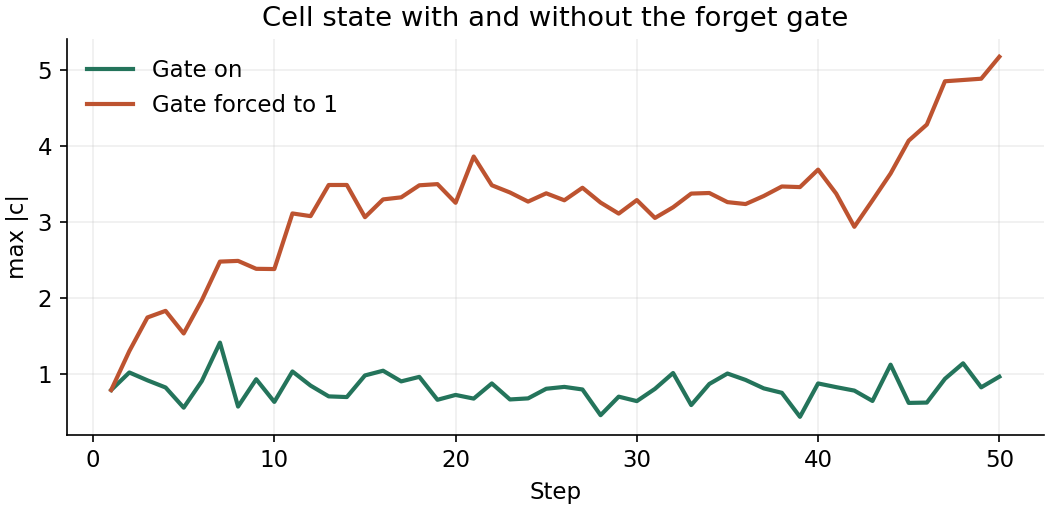

Seed 0, identical writes in both runs; only the forget gate differs.

## Part 4 — The Hero: LSTMCell

The cell above keeps `f * prev_cell`, adds `i * g`, and exposes `o * tanh(c)`. The forget gate controls retention, the input gate controls new writes, and the output gate controls the visible hidden state.

### Explain it — Untrained perplexity

Zeroing the output projection makes every logit zero, so each of the 62 characters gets probability `1/62`. The mean loss is `ln(62)` and perplexity is 62. This does not check the cell update because the zero output weights hide whatever the cell computes.

## Part 5 — Train on the Old Tongue

Use a sorted vocabulary, 512-dimensional embeddings and hidden states, batch size 16, BPTT 25, and SGD at 0.032. The verbatim script runs its 30-batch demo; the following cell starts a fresh seed-0 model and trains the required 60 batches. Perplexity is the exponential of the running mean loss per character.


The current `data/qa_oldtongue.txt` contains bAbI sentences (42 characters), rather than the required Shakespeare corpus (62). These measured results therefore start at 42, not the handout's 62; the synthetic untrained-perplexity test still checks 62. Use the Shakespeare download in the README to reproduce the assignment reference curve.

In [6]:
import numpy as np
from tensor import Tensor
from layers import Embedding, LSTMCell, CrossEntropyLoss
from optim import SGD

def load_corpus(path="data/qa_oldtongue.txt"):
    raw = open(path, "r").read()
    # sorted: the same map on every run
    vocab = sorted(set(raw))
    word2index = {ch: i for i, ch in enumerate(vocab)}
    indices = np.array([word2index[ch] for ch in raw])
    return raw, vocab, word2index, indices

def make_batches(indices, batch_size=16, bptt=25):
    n = indices.shape[0] // batch_size # characters per column
    batched = indices[:n * batch_size].reshape(batch_size, n).transpose()
    n_bptt = (n - 1) // bptt # whole chunks of bptt steps
    inputs = batched[0:-1][:n_bptt * bptt].reshape(n_bptt, bptt, batch_size)
    targets = batched[1:][:n_bptt * bptt].reshape(n_bptt, bptt, batch_size)
    # targets: the inputs shifted by one
    return inputs, targets

def build_model(vocab_size, alpha=0.032, seed=0):
    np.random.seed(seed)
    embed = Embedding(vocab_size=vocab_size, dim=512)
    model = LSTMCell(n_inputs=512, n_hidden=512, n_output=vocab_size)
    # every logit 0: a uniform guess
    model.w_ho.weight.data *= 0
    criterion = CrossEntropyLoss()
    optim = SGD(parameters=model.get_parameters() + embed.get_parameters(),
    alpha=alpha)
    return embed, model, criterion, optim

def train(embed, model, criterion, optim, inputs, targets, max_batches=None):
    bptt, batch_size = inputs.shape[1], inputs.shape[2]
    n = len(inputs) if max_batches is None else min(max_batches, len(inputs))
    hidden = model.init_hidden(batch_size=batch_size)
    total_loss, perplexities = 0, []

    for batch_i in range(n):
        # truncated BPTT: keep the state's numbers, cut its history
        hidden = (Tensor(hidden[0].data, autograd=True),
        Tensor(hidden[1].data, autograd=True))
        loss = None
        for t in range(bptt):
            inp = Tensor(inputs[batch_i][t], autograd=True)
            output, hidden = model.forward(input=embed.forward(input=inp),
            hidden=hidden)
            target = Tensor(targets[batch_i][t], autograd=True)
            step_loss = criterion.forward(output, target)
            loss = step_loss if loss is None else step_loss + loss
        loss.backward()
        optim.step()
        total_loss += loss.data / bptt # mean loss per character
        perplexities.append(float(np.exp(total_loss / (batch_i + 1))))
    return perplexities

if __name__ == "__main__":
    raw, vocab, word2index, indices = load_corpus("data/qa_oldtongue.txt")
    print("characters:", len(raw), " vocab size:", len(vocab))
    ib, tb = make_batches(indices)
    print("chunks per epoch:", len(ib), " each chunk:", ib[0].shape)
    # (a) train 30 batches (seed 0, sorted vocab, alpha 0.032) -> descent from 62
    embed, model, crit, optim = build_model(len(vocab))
    ppl = train(embed, model, crit, optim, ib, tb, max_batches=30)
    for b in (1, 5, 10, 15, 20, 25, 30):
        print(" batch {:2d}: {:.10f}".format(b, ppl[b - 1]))
    flat = all(ppl[k + 1] <= ppl[k] + 1e-9 for k in range(len(ppl) - 1))
    print("never rises:", flat)
    # (b) the thesis: gated cell state bounded, ungated runs away (50 steps)
    sigmoid = lambda x: 1 / (1 + np.exp(-x))

    def lstm_cell_state_horizon(steps=50, forget_gate=True, seed=0):
        rng = np.random.RandomState(seed)
        c, norms = np.zeros(16), []
        for _ in range(steps):
            x = rng.randn(16)
            f_pre = rng.randn(16) # always drawn: same writes either way
            f = sigmoid(f_pre) if forget_gate else np.ones(16)
            i = sigmoid(rng.randn(16))
            c = f * c + i * np.tanh(x) # keep f of the old, write i of the new
            norms.append(float(np.max(np.abs(c))))
        return norms
    gated = lstm_cell_state_horizon(steps=50, forget_gate=True)
    ungated = lstm_cell_state_horizon(steps=50, forget_gate=False)
    row = "{:<16}: step1 |c|={:.4f} step50 |c|={:.4f}"
    print()
    print(row.format("forget gate ON", gated[0], gated[-1]))
    print(row.format("forget gate OFF", ungated[0], ungated[-1]))
    print("ratio at step 50: {:.1f}x".format(ungated[-1] / gated[-1]))
    top = np.tanh(ungated[-1])
    print("tanh of the ungated |c| at step 50: {:.7f}".format(top))


characters: 94346  vocab size: 42
chunks per epoch: 235  each chunk: (25, 16)
 batch  1: 42.0000000000
 batch  5: 41.9995087369
 batch 10: 41.9947504354
 batch 15: 41.9332568368
 batch 20: 40.5296369051
 batch 25: 36.9938231201
 batch 30: 34.6403037174
never rises: True

forget gate ON  : step1 |c|=0.7849 step50 |c|=0.9607
forget gate OFF : step1 |c|=0.7849 step50 |c|=5.1787
ratio at step 50: 5.4x
tanh of the ungated |c| at step 50: 0.9999365


### Explain it — Detaching the state

Re-wrapping keeps the hidden and cell-state values from the previous chunk. It cuts their links to the old computation graph, so the next backward pass only covers the current 25 steps. This bounds the history being differentiated and avoids backpropagating through an already-used graph.

In [7]:
embed, model, criterion, optimizer = build_model(len(vocab), seed=0)
perplexities = train(embed, model, criterion, optimizer, ib, tb, max_batches=60)
assert len(perplexities) == 60
for batch in (1, 30, 60):
    print("Batch {} perplexity: {:.10f}".format(batch, perplexities[batch - 1]))


Batch 1 perplexity: 42.0000000000
Batch 30 perplexity: 34.6403037174
Batch 60 perplexity: 29.1816567534


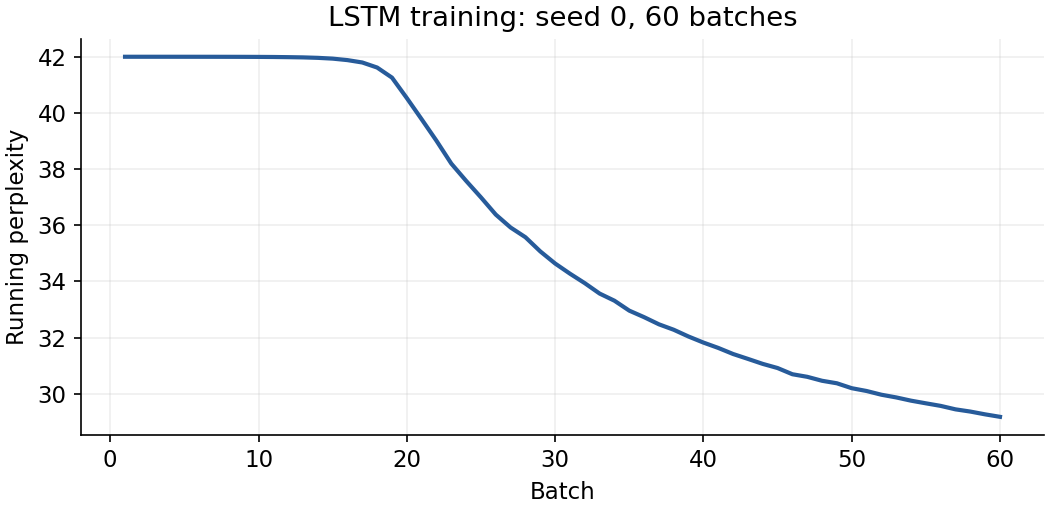

The saved curve comes from the seed-0, 60-batch run with the settings above.

## Part 6 — Tests

Run the original suite below, followed by a notebook check of all ten exploding gradients and the gated-versus-ungated comparison.

In [8]:
import numpy as np
from tensor import Tensor
from layers import Embedding, CrossEntropyLoss, LSTMCell
from exploding_gradients import exploding
import train_lstm as T

def test_index_select():
    x = Tensor(np.eye(5), autograd=True)
    x.index_select(Tensor([[1, 2, 3], [2, 3, 4]])).backward()
    assert np.all(x.grad.data[:, 0].flatten() == [0,1,2,2,1]), f"Rows selected incorrectly, expected [0,1,2,2,1], got {x.grad.data[:, 0].flatten()}"

def test_untrained_perplexity():
    np.random.seed(0)
    vocab_size = 62
    embed = Embedding(vocab_size, 512)
    model = LSTMCell(512, 512, vocab_size)
    model.w_ho.weight.data *= 0
    chars = Tensor(np.arange(16))
    hidden = model.init_hidden(batch_size=16)
    output, _ = model.forward(embed.forward(chars), hidden)
    loss = CrossEntropyLoss().forward(output, Tensor(np.arange(16)))
    assert np.isclose(np.exp(loss.data), vocab_size), f"Untrained perplexity must be close to vocab_size ({vocab_size}), got {np.exp(loss.data)}"

def test_one_step_decreases_loss():
    raw, vocab, w2i, indices = T.load_corpus()
    bi, bt = T.make_batches(indices)
    embed, model, crit, optim = T.build_model(len(vocab))
    bptt, batch_size = bi.shape[1], bi.shape[2]
    hidden = model.init_hidden(batch_size=batch_size)
    first_loss = train_step(hidden, bptt, bi, bt, model, embed, crit, optim)
    second_loss = train_step(hidden, bptt, bi, bt, model, embed, crit, optim)
    assert np.all(second_loss < first_loss), f"One optimizer step should lower the LSTM's loss, got first loss={first_loss}, second loss={second_loss}"

def test_exploding_gradients():
    step = np.random.randint(5, 20)
    ge = exploding(step)
    mags = [int(round(np.max(np.abs(g)))) for g in ge]
    assert mags[-1] == 5 ** step, f"Gradient must explode, expected {5 ** step}, got {mags[-1]}"

def train_step(hidden, bptt, bi, bt, model, embed, crit, optim):
    hidden = (Tensor(hidden[0].data, autograd=True),
              Tensor(hidden[1].data, autograd=True))

    loss = None
    for t in range(bptt):
        inp = Tensor(bi[0][t], autograd=True)
        output, hidden = model.forward(input=embed.forward(input=inp),
                                       hidden=hidden)
        target = Tensor(bt[0][t], autograd=True)
        step_loss = crit.forward(output, target)
        loss = step_loss if loss is None else step_loss + loss
    loss.backward()
    optim.step()
    return loss.data / bptt

if __name__ == "__main__":
    tests = [name for name in dir() if name.startswith("test_")]
    for test_name in sorted(tests):
        test_func = globals()[test_name]
        try:
            test_func()
            print(f" PASS: {test_name}")
        except AssertionError as e:
            print(f" FAIL (AssertionError): {test_name} -- {e}")

 PASS: test_exploding_gradients
 PASS: test_index_select
 PASS: test_one_step_decreases_loss
 PASS: test_untrained_perplexity


In [9]:
assert all(np.all(gradient == 5 ** step)
           for step, gradient in enumerate(exploding(10), start=1))
assert np.isclose(gated[0], ungated[0])
assert max(gated) < 2 and ungated[-1] > 5 * gated[-1]
print("PASS: full exploding sequence and gated/ungated comparison")


PASS: full exploding sequence and gated/ungated comparison


### Run summary

Untrained perplexity: **42.00**. Running perplexity: **34.64** at batch 30 and **29.18** at batch 60. All four tests in the original suite and the additional notebook comparison passed in a fresh Python process.


The current `data/qa_oldtongue.txt` contains bAbI sentences (42 characters), rather than the required Shakespeare corpus (62). These measured results therefore start at 42, not the handout's 62; the synthetic untrained-perplexity test still checks 62. Use the Shakespeare download in the README to reproduce the assignment reference curve. Sequential execution passed in a fresh Python process; interactive Jupyter Restart & Run All was not verified.

## Part 7 — Reading the Holocron

### Holocron — Reading

Setting no gate on remembrance means forcing the forget gate to `f = 1`. The update becomes `c_t = c_(t-1) + i * g`: every new write is added without reducing the previous memory. With the same seed and writes, both versions start near 0.78. By step 50, the gated state has a maximum absolute component near 0.96, while the ungated state reaches about 5.18. The ungated run reaches about 10 by step 200 and 34 by step 2000. It wanders rather than increasing every step, but the recurrence has no mechanism to forget old writes.

The visible state is still `h = o * tanh(c)`. As a component of the cell state grows large, tanh approaches either -1 or 1, so that component's exposed view saturates instead of growing with the memory. The direct gradient factor along the cell-state belt is one when `f = 1`; it is the stored state that runs away, not an exploding gradient down that belt.

Both passages share “each moment feeding the next.” Gold warns about that cycle; green promises power from it. The forget gate costs the chance to hold every detail unchanged. Letting some details fade keeps new lessons from being buried beneath accumulated memory. Doran refuses that cost and loses the person the memory was supposed to serve.